# Escenarios de redistribucion de cultivos

Construye intercambios exclusivamente entre cultivos con modelo validado y esquema historico compatible. Conserva la superficie total de cada municipio-ciclo-modalidad y la superficie nacional de cada cultivo. Por tanto, estima una relocalizacion territorial, no una expansion agricola ni la sustitucion completa de la canasta nacional.

In [1]:
from IPython.display import display
import pandas as pd

from proyecto_agronomia.config import PROCESSED_DATA_DIR
from proyecto_agronomia.datasets.inegi import obtener_municipios_inegi
from proyecto_agronomia.modeling.cultivos import (
    catalogar_cultivos, cargar_registros_cultivos, seleccionar_principales,
)
from proyecto_agronomia.modeling.redistribucion import (
    CLAVES_BLOQUE, construir_matriz_potencial, crear_escenarios,
    cultivos_con_modelo_valido, optimizar_intercambios,
)
from proyecto_agronomia.plots import (
    crear_mapa_redistribucion_cultivos,
    crear_mapa_redistribucion_por_ciclo,
)

2026-11-16 19:30:12.844 | INFO     | proyecto_agronomia.config:<module>:14 - PROJ_ROOT path is: B:\MCD2\JW\agro\proyecto_agronomia


In [2]:
RUTA_DATOS = PROCESSED_DATA_DIR / 'agricultura_clima_edafologia_historial_2003_2025.csv'
CANTIDAD_CULTIVOS = 385  # maximo; solo pasan cultivos con cobertura y modelo valido
VERSION_MODELOS = 'v1_principales'
R2_ESPACIAL_MINIMO = 0.50
ANIO_BASE = 2025
ANIOS_CLIMA = (2022, 2025)
MINIMO_ANIOS_HISTORIA = 3
ESCENARIOS = {'conservador': 0.10, 'intermedio': 0.25, 'exploratorio': 0.40}

if not RUTA_DATOS.is_file():
    raise FileNotFoundError(f'No se encontro el dataset historico: {RUTA_DATOS}')
print(f'Dataset para redistribucion: {RUTA_DATOS}')

Dataset para redistribucion: B:\MCD2\JW\agro\proyecto_agronomia\data\processed\agricultura_clima_edafologia_historial_2003_2025.csv


## Cultivos con modelo y calidad suficiente

In [3]:
catalogo = catalogar_cultivos(ruta=RUTA_DATOS, unidad='Tonelada')
principales = seleccionar_principales(catalogo, cantidad=CANTIDAD_CULTIVOS)
calidad_modelos = cultivos_con_modelo_valido(
    principales['Nomcultivo'].tolist(), version=VERSION_MODELOS,
    r2_espacial_minimo=R2_ESPACIAL_MINIMO,
)
display(calidad_modelos)
cultivos_elegibles = calidad_modelos.loc[calidad_modelos['elegible'], 'cultivo'].tolist()
assert len(cultivos_elegibles) >= 2, 'No hay suficientes modelos confiables para intercambiar.'
print(f'Cultivos incluidos ({len(cultivos_elegibles)}):', cultivos_elegibles)
print('Cultivos excluidos por calidad:', calidad_modelos.loc[~calidad_modelos['elegible'], 'cultivo'].tolist())

,cultivo,version,esquema_compatible,modelo,particion,registros,mae,rmse,r2,sesgo,elegible
0,Mamey,v1_principales,True,random_forest,prueba_espaciotemporal,76,1.216610,1.786971,0.960013,-0.946213,True
1,Maíz grano,v1_principales,True,random_forest,prueba_espaciotemporal,3520,0.274017,0.491907,0.952665,-0.073087,True
2,Papaya,v1_principales,True,random_forest,prueba_espaciotemporal,231,3.816833,5.861021,0.950941,-1.441286,True
3,Mango,v1_principales,True,random_forest,prueba_espaciotemporal,380,0.716592,1.079084,0.945994,-0.326184,True
4,Arroz palay,v1_principales,True,random_forest,prueba_espaciotemporal,61,0.497909,0.674569,0.944544,-0.209388,True
...,...,...,...,...,...,...,...,...,...,...,...
84,Trigo forrajero verde,v1_principales,True,random_forest,prueba_espaciotemporal,24,2.504298,4.679385,0.228151,0.756156,False
85,Haba grano,v1_principales,True,random_forest,prueba_espaciotemporal,177,0.470791,2.598864,0.080937,-0.212490,False
86,Alfalfa achicalada,v1_principales,True,random_forest,prueba_espaciotemporal,112,3.623825,7.492589,0.001445,-2.607515,False
87,Canola,v1_principales,True,hist_gradient_boosting,prueba_espaciotemporal,11,4.313012,7.847215,-0.301125,-4.101636,False


Cultivos incluidos (79): ['Mamey', 'Maíz grano', 'Papaya', 'Mango', 'Arroz palay', 'Toronja', 'Haba verde', 'Nopalitos', 'Papa', 'Chile seco', 'Trigo grano', 'Plátano', 'Chile verde', 'Naranja', 'Maíz forrajero en verde', 'Coco fruta', 'Guayaba', 'Tomate rojo', 'Triticale grano', 'Limón', 'Pastos y praderas', 'Col', 'Nuez', 'Aguacate', 'Chícharo', 'Alfalfa verde', 'Cebolla', 'Manzana', 'Sorgo forrajero en verde', 'Zarzamora', 'Café cereza', 'Tamarindo', 'Sandía', 'Frijol', 'Sábila', 'Tomate verde', 'Pera', 'Jamaica', 'Avena grano', 'Pepino', 'Melón', 'Avena forrajera en verde', 'Camote', 'Durazno', 'Cebada grano', 'Coliflor', 'Cebada forrajera en verde', 'Mandarina', 'Garbanzo forrajero', 'Zanahoria', 'Lechuga', 'Ebo', 'Garbanzo grano', 'Caña de azúcar piloncillo', 'Caña de azúcar', 'Tuna', 'Ciruela', 'Cacahuate', 'Calabacita', 'Fresa', 'Granada', 'Jícama', 'Triticale forrajero en verde', 'Uva', 'Brócoli', 'Ajo', 'Sorgo escobero', 'Calabaza', 'Elote', 'Pitahaya', 'Ejote', 'Litchi', 'Ze

## Matriz municipio-cultivo

Una combinación candidata requiere al menos tres años de historia en el mismo municipio, ciclo y modalidad. El rendimiento esperado es el promedio de predicciones bajo los climas observados entre 2022 y 2025.

In [4]:
datos_elegibles = cargar_registros_cultivos(
    cultivos_elegibles, ruta=RUTA_DATOS, unidad='Tonelada',
)
matriz_potencial = construir_matriz_potencial(
    datos_elegibles, cultivos=cultivos_elegibles, version=VERSION_MODELOS,
    anio_base=ANIO_BASE, anios_clima=ANIOS_CLIMA,
    minimo_anios_historia=MINIMO_ANIOS_HISTORIA,
)
assert set(matriz_potencial['Nomcultivo']).issubset(set(cultivos_elegibles))
display(pd.DataFrame({
    'combinaciones': [len(matriz_potencial)],
    'municipios': [matriz_potencial['cvegeo'].nunique()],
    'cultivos': [matriz_potencial['Nomcultivo'].nunique()],
    'superficie_base_ha': [matriz_potencial['superficie_base_ha'].sum()],
}))
display(matriz_potencial.head())

,combinaciones,municipios,cultivos,superficie_base_ha
0,32091,2439,79,16868797.3


,cvegeo,Nomcicloproductivo,Nommodalidad,Nomcultivo,rendimiento_esperado,rendimiento_desviacion,anios_clima,anios_historia,Nomestado,Nommunicipio,superficie_base_ha,superficie_bloque_ha
0,04002,Perennes,Riego,Mamey,16.488774,1.684349,4,18,Campeche,Campeche,20.00,2570.00
1,06003,Perennes,Temporal,Mamey,12.481380,0.161395,4,19,Colima,Comala,6.70,5290.40
2,06007,Perennes,Riego,Mamey,4.968267,0.141919,4,4,Colima,Manzanillo,8.25,5844.81
3,06009,Perennes,Riego,Mamey,4.894073,0.100567,4,19,Colima,Tecomán,41.25,29195.90
4,07028,Perennes,Temporal,Mamey,5.583716,0.230138,4,21,Chiapas,Chiapilla,5.00,285.76


## Optimización y escenarios parciales

In [5]:
superficie_optima, diagnostico = optimizar_intercambios(matriz_potencial)
escenarios = crear_escenarios(matriz_potencial, superficie_optima, ESCENARIOS)
display(pd.Series(diagnostico, name='valor').to_frame())

resumen_escenarios = [{
    'escenario': 'base',
    'produccion_predicha_t': (escenarios['superficie_base_ha'] * escenarios['rendimiento_esperado']).sum(),
    'superficie_reasignada_ha': 0.0,
}]
for nombre in ESCENARIOS:
    resumen_escenarios.append({
        'escenario': nombre,
        'produccion_predicha_t': escenarios[f'produccion_{nombre}_t'].sum(),
        'superficie_reasignada_ha': escenarios[f'cambio_{nombre}_ha'].clip(lower=0).sum(),
    })
resumen_escenarios = pd.DataFrame(resumen_escenarios)
base_t = resumen_escenarios.loc[resumen_escenarios['escenario'].eq('base'), 'produccion_predicha_t'].iloc[0]
resumen_escenarios['ganancia_t'] = resumen_escenarios['produccion_predicha_t'] - base_t
resumen_escenarios['ganancia_pct'] = resumen_escenarios['ganancia_t'] / base_t * 100
display(resumen_escenarios)

,valor
exito,True
mensaje,Optimization terminated successfully. (HiGHS S...
produccion_base_predicha,230277018.458389
produccion_optima_predicha,290866374.494978


,escenario,produccion_predicha_t,superficie_reasignada_ha,ganancia_t,ganancia_pct
0,base,2.302770e+08,0.000000e+00,0.000000e+00,0.000000
1,conservador,2.363360e+08,7.590289e+05,6.058936e+06,2.631151
2,intermedio,2.454244e+08,1.897572e+06,1.514734e+07,6.577877
3,exploratorio,2.545128e+08,3.036116e+06,2.423574e+07,10.524603


## Validar conservación de superficies

In [6]:
for nombre in ESCENARIOS:
    columna = f'superficie_{nombre}_ha'
    total_bloque = escenarios.groupby(CLAVES_BLOQUE, observed=True)[columna].sum()
    base_bloque = escenarios.groupby(CLAVES_BLOQUE, observed=True)['superficie_base_ha'].sum()
    assert (total_bloque - base_bloque).abs().max() < 1e-4
    claves_cultivo = ['Nomcultivo', 'Nomcicloproductivo', 'Nommodalidad']
    total_cultivo = escenarios.groupby(claves_cultivo, observed=True)[columna].sum()
    base_cultivo = escenarios.groupby(claves_cultivo, observed=True)['superficie_base_ha'].sum()
    assert (total_cultivo - base_cultivo).abs().max() < 1e-4
print('Validacion correcta: se conservan superficies municipales y nacionales por cultivo.')

Validacion correcta: se conservan superficies municipales y nacionales por cultivo.


## Principales intercambios y guardado

In [7]:
columnas = [
    'cvegeo', 'Nomestado', 'Nommunicipio', 'Nomcicloproductivo',
    'Nommodalidad', 'Nomcultivo', 'superficie_base_ha',
    'superficie_intermedio_ha', 'cambio_intermedio_ha',
    'rendimiento_esperado', 'anios_historia', 'anios_clima',
]
display(escenarios.loc[escenarios['cambio_intermedio_ha'].gt(0), columnas]
        .nlargest(30, 'cambio_intermedio_ha'))

ruta_escenarios = PROCESSED_DATA_DIR / 'redistribucion_cultivos_principales_2025.csv'
ruta_resumen = PROCESSED_DATA_DIR / 'redistribucion_cultivos_resumen_2025.csv'
escenarios.to_csv(ruta_escenarios, index=False)
resumen_escenarios.to_csv(ruta_resumen, index=False)
print(f'Escenarios: {ruta_escenarios}')
print(f'Resumen: {ruta_resumen}')

,cvegeo,Nomestado,Nommunicipio,Nomcicloproductivo,Nommodalidad,Nomcultivo,superficie_base_ha,superficie_intermedio_ha,cambio_intermedio_ha,rendimiento_esperado,anios_historia,anios_clima
4560,32042,Zacatecas,Sombrerete,Primavera-Verano,Temporal,Maíz grano,8060.00,41110.0000,33050.0000,2.355914,23,4
4499,32010,Zacatecas,Fresnillo,Primavera-Verano,Temporal,Maíz grano,7000.00,34757.5000,27757.5000,1.602365,23,4
3634,25001,Sinaloa,Ahome,Otoño-Invierno,Riego,Maíz grano,7119.90,27670.0025,20550.1025,11.931856,23,4
4555,32039,Zacatecas,Río Grande,Primavera-Verano,Temporal,Maíz grano,1279.00,19069.0000,17790.0000,1.444946,23,4
27333,14068,Jalisco,Villa Purificación,Perennes,Temporal,Caña de azúcar,315.00,17914.7500,17599.7500,73.131344,23,4
7035,25011,Sinaloa,Guasave,Otoño-Invierno,Riego,Trigo grano,2500.00,16510.1450,14010.1450,6.480978,23,4
27155,25018,Sinaloa,Navolato,Otoño-Invierno,Riego,Garbanzo grano,9325.87,22891.6225,13565.7525,1.958437,23,4
8566,24040,San Luis Potosí,Tamuín,Perennes,Temporal,Naranja,71.00,13283.5000,13212.5000,13.093863,23,4
4534,32029,Zacatecas,Miguel Auza,Primavera-Verano,Temporal,Maíz grano,2520.00,15410.5000,12890.5000,1.620883,22,3
25486,10008,Durango,Guadalupe Victoria,Primavera-Verano,Temporal,Cebada grano,234.00,11914.5000,11680.5000,2.457083,17,4


Escenarios: B:\MCD2\JW\agro\proyecto_agronomia\data\processed\redistribucion_cultivos_principales_2025.csv
Resumen: B:\MCD2\JW\agro\proyecto_agronomia\data\processed\redistribucion_cultivos_resumen_2025.csv


## Mapas de distribución original y redistribuida

El color representa el cultivo con mayor superficie dentro del conjunto elegible en cada municipio. Ambos mapas utilizan exactamente la misma paleta.

2026-11-16 19:31:41.117 | INFO     | proyecto_agronomia.datasets.inegi:obtener_municipios_inegi:49 - Cargando municipios INEGI desde archivo local.


,cvegeo,cultivo_original,cultivo_nuevo,cambio_dominante
17,03001,Maíz grano,Calabacita,True
42,05008,Avena forrajera en verde,Trigo grano,True
51,05017,Maíz forrajero en verde,Avena forrajera en verde,True
55,05021,Sorgo forrajero en verde,Pastos y praderas,True
67,05033,Nuez,Alfalfa verde,True
76,06004,Pastos y praderas,Caña de azúcar,True
83,07001,Café cereza,Pastos y praderas,True
107,07025,Frijol,Café cereza,True
119,07037,Pastos y praderas,Caña de azúcar,True
124,07042,Maíz grano,Café cereza,True


,Nomcicloproductivo,superficie_base_ha,produccion_base_t,produccion_intermedia_t,superficie_reasignada_ha,ganancia_t,ganancia_pct
0,Otoño-Invierno,2102756.39,1.965585e+07,2.242692e+07,3.036883e+05,2.771069e+06,14.097936
1,Perennes,5858174.42,1.578352e+08,1.636628e+08,5.645806e+05,5.827562e+06,3.692181
2,Primavera-Verano,8907866.49,5.278596e+07,5.933466e+07,1.029303e+06,6.548708e+06,12.406156


Resumen por ciclo: B:\MCD2\JW\agro\proyecto_agronomia\data\processed\redistribucion_cultivos_por_ciclo_2025.csv


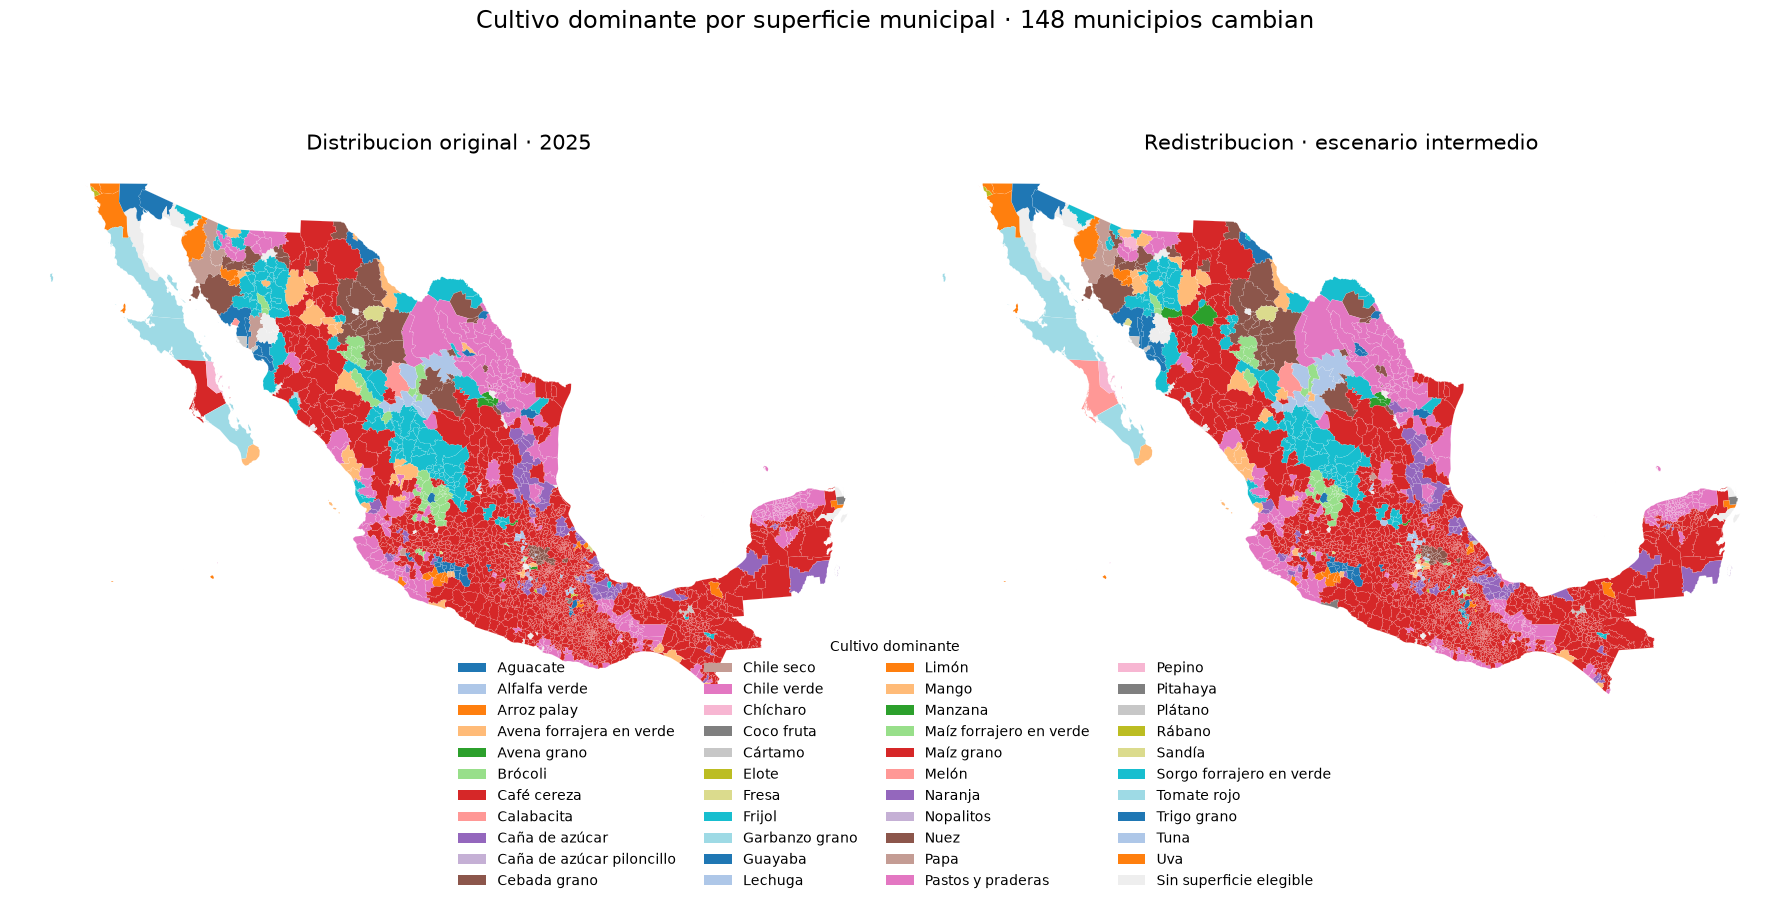

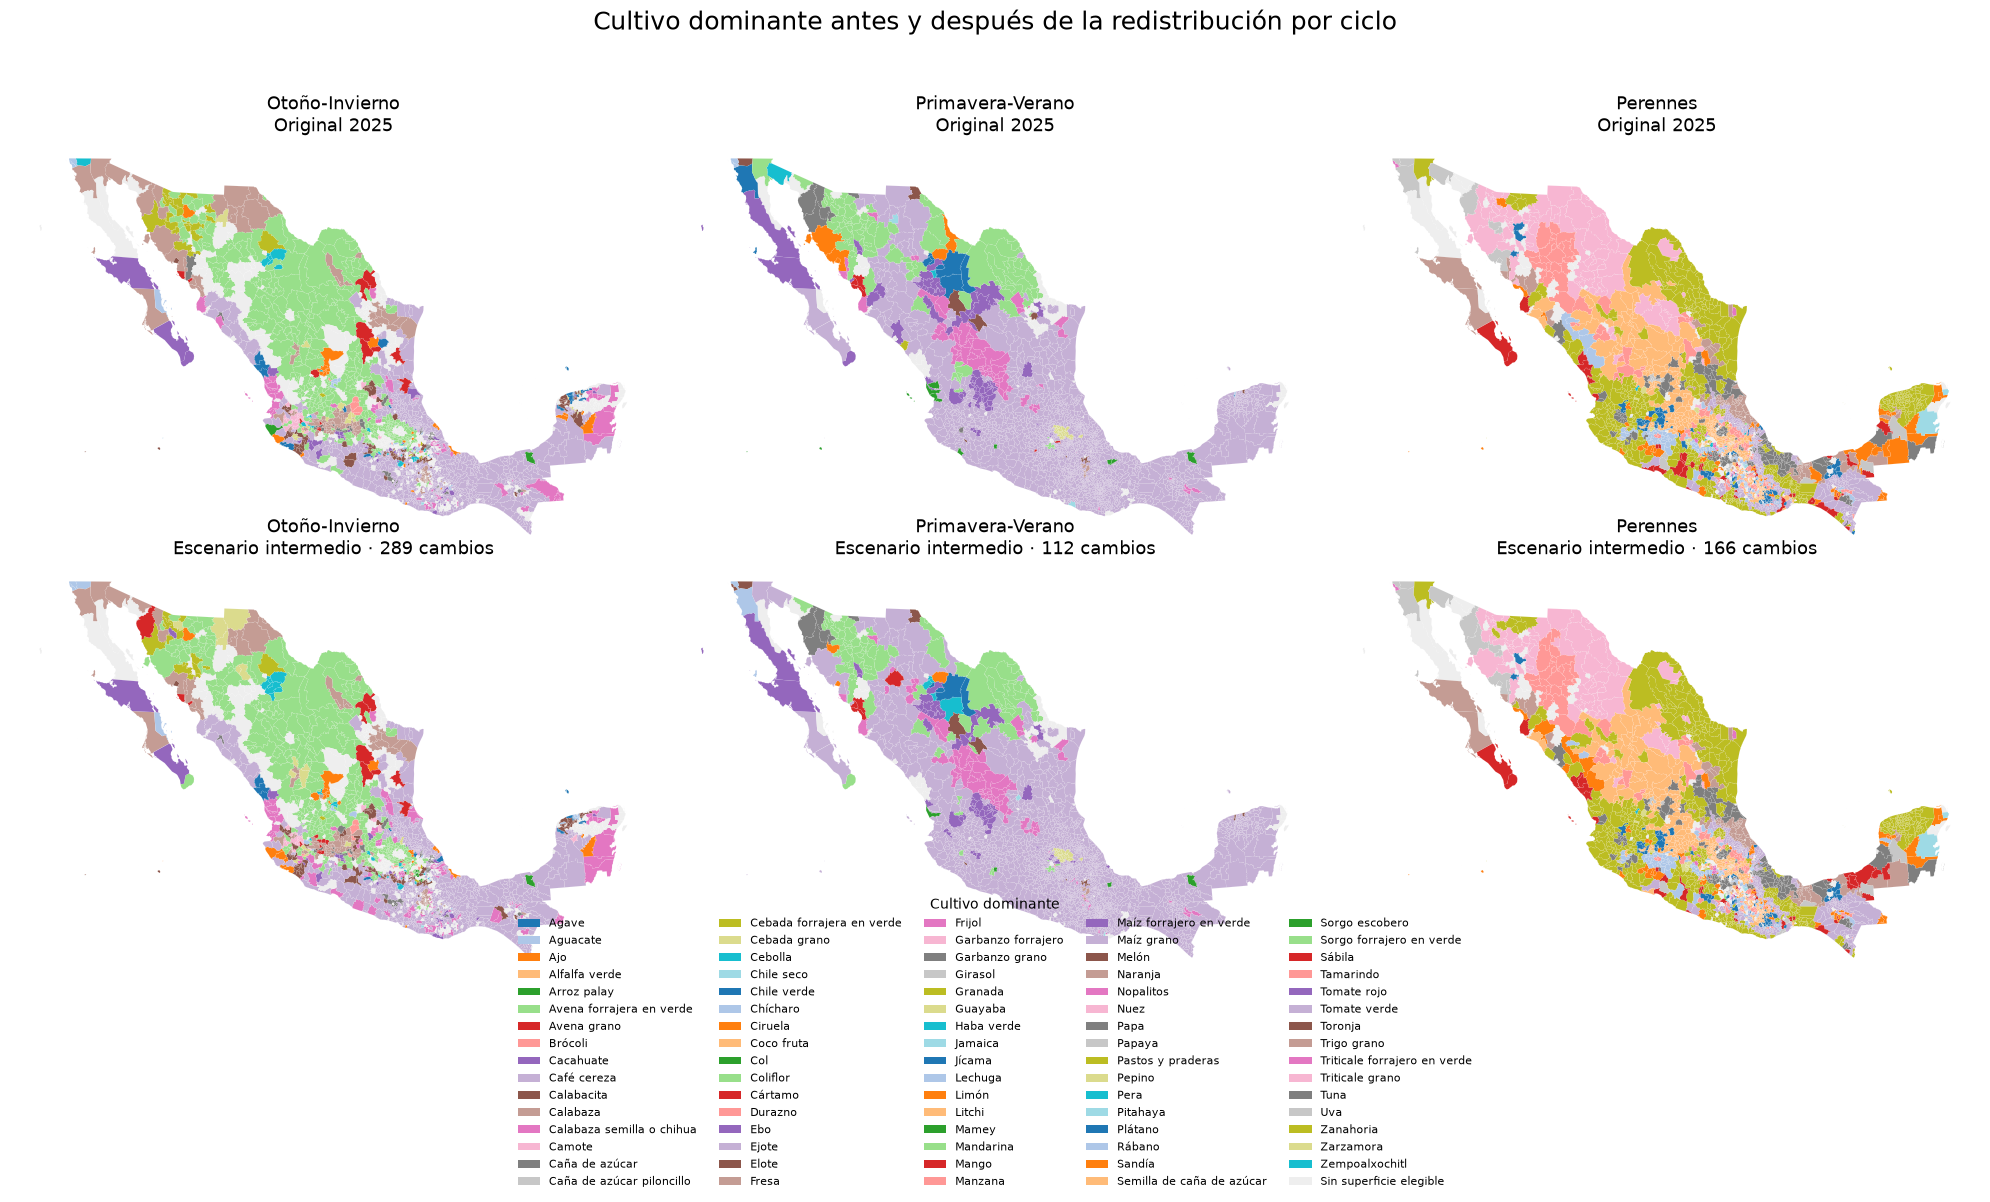

In [8]:
municipios_geo = obtener_municipios_inegi()
figura_mapa, ejes_mapa, mapa_redistribucion, cambios_dominantes = (
    crear_mapa_redistribucion_cultivos(
        escenarios, municipios_geo, escenario='intermedio',
    )
)
display(cambios_dominantes.loc[cambios_dominantes['cambio_dominante']].head(20))

resumen_ciclos = (
    escenarios.assign(
        produccion_base_t=lambda df: df['superficie_base_ha'] * df['rendimiento_esperado'],
    )
    .groupby('Nomcicloproductivo', as_index=False, observed=True)
    .agg(
        superficie_base_ha=('superficie_base_ha', 'sum'),
        produccion_base_t=('produccion_base_t', 'sum'),
        produccion_intermedia_t=('produccion_intermedio_t', 'sum'),
        superficie_reasignada_ha=('cambio_intermedio_ha', lambda serie: serie.clip(lower=0).sum()),
    )
)
resumen_ciclos['ganancia_t'] = (
    resumen_ciclos['produccion_intermedia_t'] - resumen_ciclos['produccion_base_t']
)
resumen_ciclos['ganancia_pct'] = (
    resumen_ciclos['ganancia_t'] / resumen_ciclos['produccion_base_t'] * 100
)
display(resumen_ciclos)

RUTA_RESUMEN_CICLOS = PROCESSED_DATA_DIR / 'redistribucion_cultivos_por_ciclo_2025.csv'
resumen_ciclos.to_csv(RUTA_RESUMEN_CICLOS, index=False)
figura_ciclos, ejes_ciclos, cambios_por_ciclo = crear_mapa_redistribucion_por_ciclo(
    escenarios, municipios_geo, escenario='intermedio',
)
print(f'Resumen por ciclo: {RUTA_RESUMEN_CICLOS}')

## Interpretación responsable

Los resultados son escenarios de potencial, no instrucciones de reconversión. Mantienen la canasta y superficie observadas, pero todavía no incluyen costos, demanda, disponibilidad de agua, infraestructura, rotaciones ni decisiones de productores.